# 03 · Temporal validation and leak-safe baselines

Protocol (full text: `docs/validation_protocol.md`):

* **Target:** `y(w, t, h) = dengue_cases(w, t + h weeks)` for h ∈ {2, 3, 4}, aligned by calendar date per ward.
* **Folds:** expanding window from 2016. A model for evaluation year *Y* is fitted at cutoff 31 Dec *Y−1*,
  using only rows whose target was reported by the cutoff. It is evaluated on rows whose origin
  **and** target both lie in *Y*. Validation years are 2022, 2023 and 2024.
* **Locked test:** 2025 is never evaluated here (`folds(include_test=False)`).
* **Features at origin t:** cases reported by t (`report_lag` weeks of delay), weather observed up to t,
  static ward attributes, and the calendar date of the target week.
* `oracle_weather_glm` reads post-origin weather. It is **not a forecast**, only a ceiling for what
  perfect weather knowledge would be worth.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
np.random.seed(2026)
import matplotlib.pyplot as plt
from cycler import cycler
from scipy.stats import poisson
from dengueshield import baselines, metrics
from dengueshield.data import load_panel
from dengueshield.validation import TEST_YEAR, folds, fold_sizes, split

OUT = ROOT / "reports/baselines"; OUT.mkdir(parents=True, exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK2, GRID, SURF = "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "lines.linewidth": 2,
    "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "axes.prop_cycle": cycler(color=SERIES), "savefig.dpi": 130, "savefig.bbox": "tight"})

panel = load_panel()
table = baselines.build_table(panel, report_lag=0)
print(table.shape)

(93420, 52)


## 1. Fold construction and sample counts

In [2]:
sizes = fold_sizes(table)
sizes.to_csv(OUT / "fold_sizes.csv", index=False)
for fold in folds():
    tr, ev = split(table, fold)
    assert tr.target_date.max() <= fold.cutoff < ev.origin_date.min()
    assert (ev.target_date.dt.year == fold.eval_year).all()
    assert not set(zip(tr.ward_id, tr.target_date)) & set(zip(ev.ward_id, ev.target_date))
    assert (tr.target_date.dt.year < TEST_YEAR).all() and (ev.target_date.dt.year < TEST_YEAR).all()
sizes

,fold,horizon,cutoff,n_train,n_eval,train_target_last,eval_origin_first,eval_target_first,eval_target_last
0,val_2022,2,2021-12-31,18660,3000,2021-12-27,2022-01-03,2022-01-17,2022-12-26
1,val_2022,3,2021-12-31,18600,2940,2021-12-27,2022-01-03,2022-01-24,2022-12-26
2,val_2022,4,2021-12-31,18540,2880,2021-12-27,2022-01-03,2022-01-31,2022-12-26
3,val_2023,2,2022-12-31,21780,3000,2022-12-26,2023-01-02,2023-01-16,2023-12-25
4,val_2023,3,2022-12-31,21720,2940,2022-12-26,2023-01-02,2023-01-23,2023-12-25
5,val_2023,4,2022-12-31,21660,2880,2022-12-26,2023-01-02,2023-01-30,2023-12-25
6,val_2024,2,2023-12-31,24900,3060,2023-12-25,2024-01-01,2024-01-15,2024-12-30
7,val_2024,3,2023-12-31,24840,3000,2023-12-25,2024-01-01,2024-01-22,2024-12-30
8,val_2024,4,2023-12-31,24780,2940,2023-12-25,2024-01-01,2024-01-29,2024-12-30


## 2. Multi-horizon alignment check on the real data

In [3]:
lookup = panel.set_index(["ward_id", "date"]).dengue_cases
sample = table.sample(5000, random_state=2026)
assert ((sample.target_date - sample.origin_date).dt.days == 7 * sample.horizon).all()
assert (sample.y_true.to_numpy() == lookup.loc[list(zip(sample.ward_id, sample.target_date))].to_numpy()).all()
# features are keyed to the origin: 'last' equals the case count at the origin week itself (report_lag = 0)
assert (sample["last"].to_numpy() == lookup.loc[list(zip(sample.ward_id, sample.origin_date))].to_numpy()).all()
print("alignment verified on", len(sample), "random rows across horizons", sorted(sample.horizon.unique()))

alignment verified on 5000 random rows across horizons [np.int64(2), np.int64(3), np.int64(4)]


## 3. Training-only thresholds per fold

In [4]:
thr_rows = []
for fold in folds():
    tr, _ = split(table, fold)
    for h in (2, 3, 4):
        t = metrics.thresholds(tr[tr.horizon == h].y_true)
        thr_rows.append({"fold": fold.name, "horizon": h, "outbreak_q90": t["outbreak"], "tier_edges_q60_q80_q95": t["tier_edges"]})
thr = pd.DataFrame(thr_rows); thr.to_csv(OUT / "training_thresholds.csv", index=False)
thr

,fold,horizon,outbreak_q90,tier_edges_q60_q80_q95
0,val_2022,2,9.0,"[1.0, 5.0, 13.0]"
1,val_2022,3,9.0,"[1.0, 5.0, 13.0]"
2,val_2022,4,9.0,"[1.0, 5.0, 13.0]"
3,val_2023,2,9.0,"[1.0, 5.0, 13.0]"
4,val_2023,3,9.0,"[1.0, 5.0, 13.0]"
5,val_2023,4,9.0,"[1.0, 5.0, 13.0]"
6,val_2024,2,10.0,"[1.0, 6.0, 13.0]"
7,val_2024,3,10.0,"[1.0, 6.0, 13.0]"
8,val_2024,4,10.0,"[1.0, 6.0, 13.0]"


## 4. Baselines on the three validation folds

In [5]:
models = baselines.MODELS + (baselines.ORACLE,)
preds, per_fold = baselines.run(table, report_lag=0, models=models)
# Diagnostic: MAE is minimised by the predictive median. Median of Poisson(mu) from the GLM rates.
extra = []
for (fname, h, m), d in preds[preds.model.isin(["poisson_glm", baselines.ORACLE])].groupby(["fold", "horizon", "model"]):
    tr, _ = split(table, next(f for f in folds() if f.name == fname))
    med = poisson.median(np.maximum(d.y_pred.to_numpy(), 1e-9))
    extra.append({"fold": fname, "horizon": h, "model": m + "_poisson_median",
                  **metrics.flatten(metrics.evaluate(d.y_true, med, metrics.thresholds(tr[tr.horizon == h].y_true)))})
per_fold = pd.concat([per_fold, pd.DataFrame(extra)], ignore_index=True)
per_fold.to_csv(OUT / "metrics_by_fold.csv", index=False)

keep = ["all_mae", "all_rmse", "all_poisson_dev", "all_bias", "all_under_rate", "zero_mae", "positive_mae",
        "high_mae", "high_bias", "outbreak_precision", "outbreak_recall", "outbreak_f1", "tier_accuracy"]
summary = per_fold.groupby(["horizon", "model"], sort=False)[keep].mean()
summary.insert(1, "mae_fold_sd", per_fold.groupby(["horizon", "model"], sort=False).all_mae.std())
summary = summary.reset_index().sort_values(["horizon", "all_mae"])
summary.to_csv(OUT / "metrics_summary.csv", index=False)
summary.round(3)

,horizon,model,all_mae,mae_fold_sd,all_rmse,all_poisson_dev,all_bias,all_under_rate,zero_mae,positive_mae,high_mae,high_bias,outbreak_precision,outbreak_recall,outbreak_f1,tier_accuracy
22,2,poisson_glm_poisson_median,1.094,0.172,2.189,1.256,-0.320,0.241,0.122,2.324,4.088,-2.983,0.799,0.568,0.661,0.783
21,2,oracle_weather_glm_poisson_median,1.108,0.176,2.226,1.281,-0.345,0.245,0.121,2.357,4.207,-3.004,0.803,0.543,0.645,0.780
5,2,poisson_glm,1.128,0.165,2.156,0.906,-0.189,0.272,0.214,2.284,3.992,-2.802,0.824,0.528,0.639,0.782
6,2,oracle_weather_glm,1.141,0.169,2.195,0.922,-0.217,0.275,0.214,2.315,4.117,-2.851,0.824,0.508,0.624,0.778
2,2,seasonal_avg,1.458,0.185,2.893,1.421,-0.200,0.250,0.255,2.980,4.867,-4.335,0.651,0.512,0.558,0.744
3,2,last_known,2.142,0.449,4.111,4.486,-0.000,0.240,0.412,4.325,6.705,-4.356,0.482,0.482,0.482,0.652
4,2,moving_avg_4,2.172,0.385,3.927,3.778,-0.001,0.269,0.735,3.991,6.303,-5.183,0.458,0.410,0.431,0.627
1,2,ward_mean,3.607,0.500,4.873,6.616,-0.280,0.311,2.645,4.795,10.660,-10.660,NaN,0.000,NaN,0.204
0,2,global_mean,3.627,0.492,4.933,6.824,-0.280,0.310,2.675,4.803,10.995,-10.995,NaN,0.000,NaN,0.204
23,3,oracle_weather_glm_poisson_median,1.131,0.179,2.248,1.304,-0.351,0.249,0.126,2.357,4.207,-3.004,0.803,0.543,0.645,0.776


In [6]:
mae = per_fold.pivot_table(index=["model"], columns=["horizon", "fold"], values="all_mae")
mae.round(3).to_csv(OUT / "mae_by_fold_wide.csv")
mae.round(3)

horizon                                  2                          3                          4                  
fold                              val_2022 val_2023 val_2024 val_2022 val_2023 val_2024 val_2022 val_2023 val_2024
model                                                                                                             
global_mean                          3.870    3.951    3.061    3.898    3.980    3.071    3.928    4.011    3.081
last_known                           2.252    2.525    1.647    2.563    2.857    1.860    2.984    2.959    2.109
moving_avg_4                         2.331    2.452    1.734    2.655    2.724    1.974    2.965    3.100    2.265
oracle_weather_glm                   1.280    1.190    0.953    1.306    1.214    0.972    1.333    1.238    0.991
oracle_weather_glm_poisson_median    1.253    1.160    0.913    1.278    1.182    0.931    1.305    1.206    0.949
poisson_glm                          1.272    1.165    0.947    1.426    1.239    1.077    1.680    1.575    1.478
poisson_glm_poisson_median           1.246    1.129    0.907    1.407    1.203    1.030    1.652    1.542    1.418
seasonal_avg                         1.594    1.531    1.247    1.626    1.562    1.272    1.660    1.593    1.297
ward_mean                            3.856    3.933    3.031    3.884    3.962    3.040    3.913    3.992    3.049

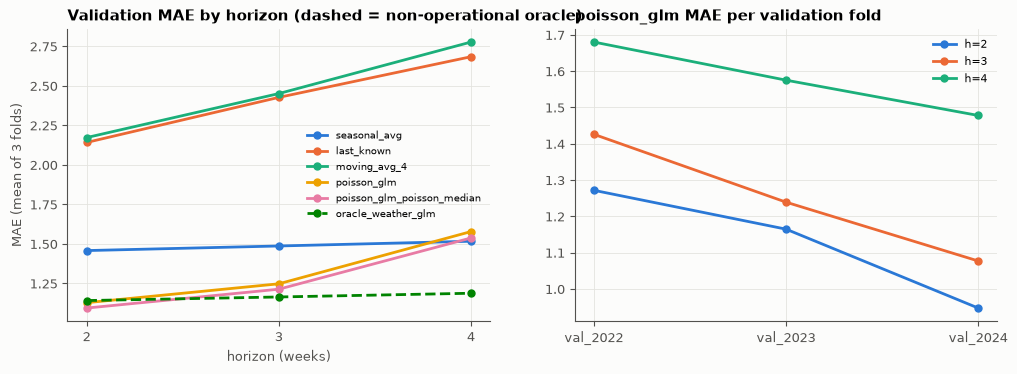

In [7]:
show = ["seasonal_avg", "last_known", "moving_avg_4", "poisson_glm", "poisson_glm_poisson_median", baselines.ORACLE]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
s = summary.set_index(["model", "horizon"]).all_mae
for m, c in zip(show, SERIES):
    v = s.loc[m]; ls = "--" if m == baselines.ORACLE else "-"
    ax[0].plot(v.index, v.values, marker="o", ms=5, color=c, ls=ls, label=m)
ax[0].set_xticks([2, 3, 4]); ax[0].set_xlabel("horizon (weeks)"); ax[0].set_ylabel("MAE (mean of 3 folds)")
ax[0].set_title("Validation MAE by horizon (dashed = non-operational oracle)"); ax[0].legend(fontsize=7.5)
g = per_fold[per_fold.model == "poisson_glm"].pivot(index="fold", columns="horizon", values="all_mae")
for h, c in zip(g.columns, SERIES):
    ax[1].plot(g.index, g[h], marker="o", ms=5, color=c, label=f"h={h}")
ax[1].set_title("poisson_glm MAE per validation fold"); ax[1].legend(fontsize=8)
fig.savefig(OUT / "baseline_mae.png"); plt.show()

## 5. Error slices: city, ward, zero / positive / high-incidence

In [8]:
by_city = metrics.grouped(preds, ["model", "horizon", "city"]).reset_index(names=["model", "horizon", "city"])
by_city.to_csv(OUT / "metrics_by_city.csv", index=False)
by_ward = metrics.grouped(preds[preds.model == "poisson_glm"], ["horizon", "ward_id"]).reset_index(names=["horizon", "ward_id"])
by_ward.to_csv(OUT / "poisson_glm_metrics_by_ward.csv", index=False)
display(by_city[by_city.model == "poisson_glm"].pivot(index="city", columns="horizon", values="mae").round(3))
display(by_ward.groupby("horizon").mae.describe().round(3))
summary[summary.model.isin(["seasonal_avg", "poisson_glm", "poisson_glm_poisson_median"])][
    ["horizon", "model", "zero_mae", "positive_mae", "high_mae", "high_bias", "all_under_rate"]].round(3)

horizon,2,3,4
city,,,
Chattogram,1.090,1.208,1.558
Dhaka North,1.130,1.247,1.545
Dhaka South,1.117,1.229,1.561
Gazipur,1.270,1.386,1.810
Narayanganj,1.080,1.248,1.573


,count,mean,std,min,25%,50%,75%,max
horizon,,,,,,,,
2,60.0,1.127,0.216,0.679,0.947,1.131,1.271,1.679
3,60.0,1.246,0.270,0.749,1.034,1.202,1.437,1.834
4,60.0,1.577,0.364,0.995,1.307,1.518,1.846,2.543


,horizon,model,zero_mae,positive_mae,high_mae,high_bias,all_under_rate
22,2,poisson_glm_poisson_median,0.122,2.324,4.088,-2.983,0.241
5,2,poisson_glm,0.214,2.284,3.992,-2.802,0.272
2,2,seasonal_avg,0.255,2.980,4.867,-4.335,0.250
24,3,poisson_glm_poisson_median,0.183,2.472,4.356,-2.669,0.238
12,3,poisson_glm,0.272,2.440,4.276,-2.487,0.264
9,3,seasonal_avg,0.264,2.980,4.867,-4.335,0.255
16,4,seasonal_avg,0.273,2.982,4.867,-4.335,0.260
26,4,poisson_glm_poisson_median,0.223,3.093,5.400,-3.500,0.234
19,4,poisson_glm,0.320,3.067,5.298,-3.334,0.259


## 6. Reporting-delay sensitivity (cases known one week after the origin)

In [9]:
lag_table = baselines.build_table(panel, report_lag=1)
_, lag_fold = baselines.run(lag_table, report_lag=1, models=("seasonal_avg", "last_known", "moving_avg_4", "poisson_glm"))
lag = lag_fold.groupby(["horizon", "model"]).all_mae.mean().rename("mae_report_lag_1").reset_index()
lag = lag.merge(summary[["horizon", "model", "all_mae"]].rename(columns={"all_mae": "mae_report_lag_0"}))
lag["delta"] = lag.mae_report_lag_1 - lag.mae_report_lag_0
lag.to_csv(OUT / "report_lag_sensitivity.csv", index=False)
lag.round(4)

,horizon,model,mae_report_lag_1,mae_report_lag_0,delta
0,2,last_known,2.3787,2.1416,0.2372
1,2,moving_avg_4,2.4025,2.1724,0.2301
2,2,poisson_glm,1.1258,1.1279,-0.0020
3,2,seasonal_avg,1.4575,1.4575,0.0000
4,3,last_known,2.6298,2.4267,0.2031
5,3,moving_avg_4,2.7209,2.4508,0.2701
6,3,poisson_glm,1.2485,1.2473,0.0013
7,3,seasonal_avg,1.4866,1.4866,0.0000
8,4,last_known,2.8540,2.6839,0.1701
9,4,moving_avg_4,3.0692,2.7767,0.2926


## Reading the results

* The best operational baseline is `poisson_glm` at h=2 and h=3, and `seasonal_avg` at h=4. Point
  estimates and per-fold spreads are in `metrics_summary.csv` and `mae_by_fold_wide.csv`.
* The gap between `poisson_glm` and the oracle grows with horizon. That gap is the value of rain
  falling after the origin, which no honest forecast can observe. Stage 2 should narrow it with
  climatology and regime-state weather expectations, not with future weather.
* Using the Poisson median instead of the mean is a free MAE gain for any count model. It is a
  decision for Stage 2 because it trades RMSE and calibration for MAE.
* Threshold metrics (outbreak precision and recall, tier accuracy) use training-quantile operating points
  (q90 outbreak; q60/q80/q95 tiers). These are not official epidemiological cutoffs.